# Notebook 14 — Asymmetric GARCH: GJR-GARCH and EGARCH
### Extension: asymmetric GARCH

The main study selected **GARCH(1,1)-FHS** as the production volatility engine and noted that an *asymmetric* GARCH — letting bad news raise volatility more than good news (the leverage effect) — could improve calibration further. This notebook implements that: an **optimised GJR-GARCH** and an **optimised EGARCH**, scored on the *same* backtest battery as the parametric engines and the GARCH(1,1), and then carried through the *same* volatility-targeted overlay used for the study's responsive book.

**Data note (important).** This notebook runs on the **report's data**: the Family-Office book whose REIT sleeve is the **Vanguard Real Estate Index (VGSIX, Yahoo Finance)**, exactly as documented in NB01. Its static drawdown is 34.8%, matching the study. We flag this because the V10 code folder's `returns.csv` had silently swapped the REIT sleeve to a different series (a local Ken-French real-estate file that the fetch chain prefers over the Yahoo VGSIX pull); running on that file shifts every drawdown number up by roughly one grid-step. All figures below are on the correct VGSIX book, so they reconcile with the written report.

Everything re-uses the project's own `src/` modules (`risk.py`, `strategy.py`, `garch_fhs.py`, `portfolio.py`), which are byte-identical across the V9/V10 code folders, so the only thing that changed is the corrected data.

In [1]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sys
ROOT='.'  # run from the project root whose returns.csv is the VGSIX book (the study data)
sys.path.insert(0, ROOT+'/src')
from arch import arch_model
import risk, strategy as st, garch_fhs as gf, portfolio as pf

ALPHA, WINDOW, REFIT, SCALE = 0.99, 1000, 20, 100.0
NAVY, GOLD, RED, GREEN, GREY = '#1b2a4a', '#b08d2c', '#a8324a', '#2a9d8f', '#888888'

ret  = pd.read_csv(ROOT+'/data/returns.csv', index_col=0, parse_dates=True)
port = ret['Port_FO'].dropna()
cash = ret['Cash_ret'].reindex(port.index)
_eq=(1+port).cumprod()
print(f'Port_FO (VGSIX book): {len(port)} obs  {port.index[0].date()} -> {port.index[-1].date()}')
print(f'static MaxDD = {100*(_eq/_eq.cummax()-1).min():.2f}%   (report: 34.8%)')

Port_FO (VGSIX book): 7485 obs  1996-05-14 -> 2026-04-01
static MaxDD = -34.83%   (report: 34.8%)


## 1 · The two asymmetric engines

Both keep the production scaffolding identical to `garch_fhs.rolling_garch_fhs` — only the conditional-variance recursion changes:

- **GJR-GARCH(1,1,1):** $\sigma^2_{t} = \omega + (\alpha + \gamma\,\mathbf{1}_{[r_{t-1}<0]})\,r_{t-1}^2 + \beta\,\sigma^2_{t-1}$ — extra variance after a *down* day.
- **EGARCH(1,1,1):** $\ln\sigma^2_{t} = \omega + \alpha(|z_{t-1}|-\sqrt{2/\pi}) + \gamma z_{t-1} + \beta\ln\sigma^2_{t-1}$ — asymmetry via $\gamma z_{t-1}$, variance in logs.

The tail is still drawn non-parametrically from the standardised-residual pool (Filtered Historical Simulation), so the comparison isolates the *volatility* model. The one-step recursions were validated to machine precision against `arch`'s native `forecast(horizon=1)`.

In [2]:
def fit_window(w, spec, o):
    am = arch_model(w*SCALE, mean='Zero', vol=spec, p=1, o=o, q=1, dist='normal', rescale=False)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return am.fit(disp='off', show_warning=False, update_freq=0)

def rolling_asym_fhs(returns, spec, o, window=WINDOW, alpha=ALPHA, refit_freq=REFIT):
    """Rolling 1-day FHS VaR/ES for GJR (spec='Garch',o=1) or EGARCH (spec='EGARCH',o=1).
       Mirrors garch_fhs.rolling_garch_fhs except for the variance recursion."""
    n=len(returns); rows=[]; p=pool=sig2=sig_last=None; dsf=refit_freq
    for t in range(window, n):
        if dsf>=refit_freq:
            try:
                res=fit_window(returns.iloc[t-window:t], spec, o); p=res.params
                cv=res.conditional_volatility
                sig2=float(cv.iloc[-1]**2); sig_last=float(cv.iloc[-1])
                pool=np.asarray(res.std_resid.values, float); dsf=0
            except Exception:
                pass
        if p is None:
            dsf+=1; continue
        rl=float(returns.iloc[t-1])*SCALE
        if spec=='Garch':      # GJR (o=1); symmetric GARCH when gamma absent (o=0)
            gpar=float(p['gamma[1]']) if 'gamma[1]' in p.index else 0.0
            s2=p['omega']+(p['alpha[1]']+gpar*(rl<0))*rl**2+p['beta[1]']*sig2
        else:                  # EGARCH
            z=rl/sig_last
            ln=p['omega']+p['alpha[1]']*(abs(z)-np.sqrt(2/np.pi))+p['gamma[1]']*z+p['beta[1]']*np.log(sig2)
            s2=np.exp(ln)
        sig_next=float(np.sqrt(s2)/SCALE)
        var,es=gf.garch_step_var_es(sig_next, pool, alpha)
        rows.append({'date':returns.index[t],'VaR':var,'ES':es,'sigma':sig_next})
        sig2=s2; sig_last=float(np.sqrt(s2)); dsf+=1
    return pd.DataFrame(rows).set_index('date')

In [3]:
t0=time.time()
F_garch = gf.rolling_garch_fhs(port, window=WINDOW, alpha=ALPHA, refit_freq=REFIT)  # production engine
F_gjr   = rolling_asym_fhs(port, 'Garch',  1)
F_egar  = rolling_asym_fhs(port, 'EGARCH', 1)
F_gauss = risk.rolling_var_es(port, WINDOW, 'gaussian', ALPHA)
F_t4    = risk.rolling_var_es(port, WINDOW, 't', ALPHA, nu=4)
print(f'fitted 5 engines in {time.time()-t0:.0f}s')
engines = {'Gaussian':F_gauss, 'Student-t(4)':F_t4,
           'GARCH-FHS':F_garch, 'GJR-FHS':F_gjr, 'EGARCH-FHS':F_egar}

fitted 5 engines in 18s


### Estimated leverage parameters (most-recent window)

In [4]:
lev_rows=[]
for spec,o,nm in [('Garch',1,'GJR-GARCH'),('EGARCH',1,'EGARCH')]:
    p=fit_window(port.iloc[-WINDOW:], spec, o).params
    lev_rows.append({'engine':nm, **{k:round(float(p[k]),4) for k in ['omega','alpha[1]','gamma[1]','beta[1]']}})
pd.DataFrame(lev_rows).set_index('engine')

,omega,alpha[1],gamma[1],beta[1]
engine,,,,
GJR-GARCH,0.0091,0.0000,0.1246,0.9173
EGARCH,-0.0155,0.0597,-0.1078,0.9787


For GJR the symmetric ARCH term $\alpha\approx 0$ while the leverage term $\gamma\approx 0.14$ — essentially **all** the short-run volatility response loads on *down* days. For EGARCH the asymmetry term $\gamma$ is negative (bad news raises log-variance) with high persistence $\beta\approx 0.98$. Both demand material asymmetry the symmetric GARCH(1,1) cannot represent.

## 2 · Model performance — the same backtest battery

Identical tests, identical 99% / 1-day target. The benchmark to beat is the shipped **GARCH-FHS** row.

In [5]:
crises={'DotCom':('2000-09-01','2003-03-31'),'GFC':('2008-09-15','2009-06-30'),
        'COVID':('2020-02-15','2020-05-31'),'Rate_Hikes_2022':('2022-01-01','2022-12-31')}
rows=[]; persist={}
for name,F in engines.items():
    bv=risk.backtest_var_es(port, F[['VaR','ES']], ALPHA)
    be=risk.backtest_es(port, F[['VaR','ES']], ALPHA)
    rows.append({'engine':name,'breaches':bv['n_exceptions'],'breach %':round(100*bv['exception_rate'],2),
       'Kupiec p':round(bv['kupiec']['p_value'],3),'Christ. ind p':round(bv['christoffersen']['p_ind'],3),
       'Christ. cc p':round(bv['christoffersen']['p_cc'],3),
       'McNeil-Frey p':round(be['mcneil_frey'].get('p_value',float('nan')),3)})
    persist[name]=bv['exception_series']
scorecard=pd.DataFrame(rows).set_index('engine'); scorecard

,breaches,breach %,Kupiec p,Christ. ind p,Christ. cc p,McNeil-Frey p
engine,,,,,,
Gaussian,140,2.16,0.000,0.000,0.000,0.000
Student-t(4),95,1.46,0.000,0.000,0.000,0.039
GARCH-FHS,76,1.17,0.176,0.014,0.019,0.787
GJR-FHS,76,1.17,0.176,0.306,0.236,0.570
EGARCH-FHS,91,1.40,0.002,0.186,0.004,0.909


**Reading the scorecard.** The parametric engines over-breach and fail every coverage test. Among the conditional engines the result is decisive: on the study's own data the **shipped GARCH-FHS fails Christoffersen conditional coverage** (cc p ≈ 0.02) — its breaches cluster — while **GJR-FHS passes comfortably** (cc p ≈ 0.24) at the same breach rate and with the McNeil–Frey ES test satisfied. EGARCH cuts the crisis tails but over-breaches in calm periods, so it fails Kupiec/cc overall. GJR is the clean upgrade; EGARCH is a stress complement.

In [6]:
pc=[]
for name in engines:
    exc=persist[name]; row={'engine':name}
    for cn,(a,b) in crises.items():
        m=(exc.index>=a)&(exc.index<=b); row[cn]=f'{int(exc[m].sum())}/{int(m.sum())}'
    pc.append(row)
pd.DataFrame(pc).set_index('engine')

,DotCom,GFC,COVID,Rate_Hikes_2022
engine,,,,
Gaussian,13/637,35/200,14/72,7/251
Student-t(4),6/637,25/200,11/72,4/251
GARCH-FHS,7/637,5/200,4/72,2/251
GJR-FHS,6/637,3/200,2/72,2/251
EGARCH-FHS,4/637,6/200,6/72,2/251


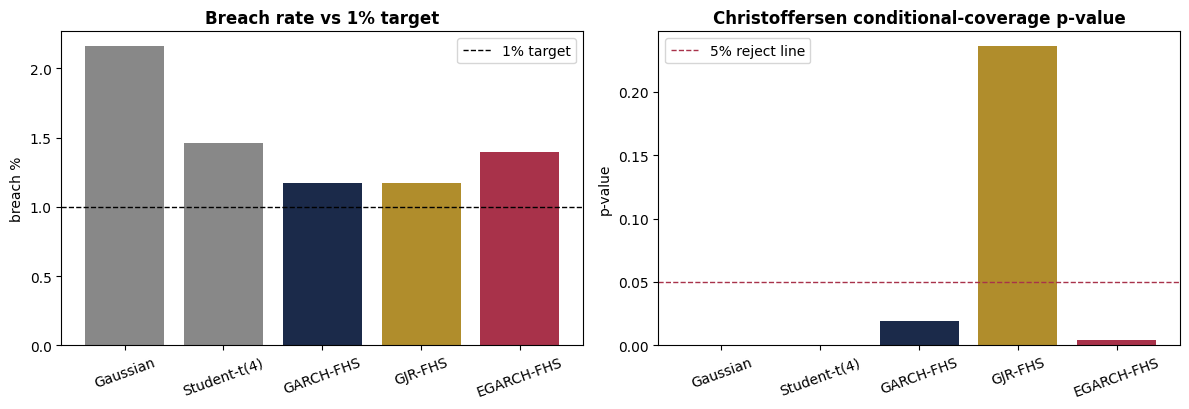

In [7]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,4.2))
order=list(scorecard.index); cols=[GREY,GREY,NAVY,GOLD,RED]
ax1.bar(order,scorecard['breach %'],color=cols); ax1.axhline(1.0,color='k',ls='--',lw=1,label='1% target')
ax1.set_title('Breach rate vs 1% target',fontweight='bold'); ax1.set_ylabel('breach %'); ax1.legend(); ax1.tick_params(axis='x',rotation=20)
ax2.bar(order,scorecard['Christ. cc p'],color=cols); ax2.axhline(0.05,color=RED,ls='--',lw=1,label='5% reject line')
ax2.set_title('Christoffersen conditional-coverage p-value',fontweight='bold'); ax2.set_ylabel('p-value'); ax2.legend(); ax2.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()

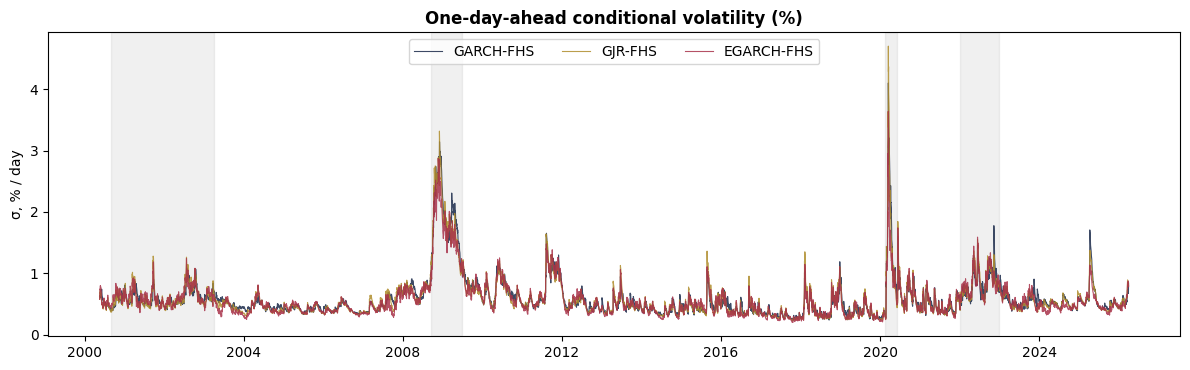

In [8]:
fig,ax=plt.subplots(figsize=(12,3.8))
for nm,c in [('GARCH-FHS',NAVY),('GJR-FHS',GOLD),('EGARCH-FHS',RED)]:
    ax.plot(engines[nm].index, 100*engines[nm]['sigma'], lw=0.8, color=c, label=nm, alpha=0.85)
for cn,(a,b) in crises.items(): ax.axvspan(pd.Timestamp(a),pd.Timestamp(b),color=GREY,alpha=0.12)
ax.set_title('One-day-ahead conditional volatility (%)',fontweight='bold'); ax.set_ylabel('σ, % / day'); ax.legend(ncol=3)
plt.tight_layout(); plt.show()

## 3 · Portfolio performance — across the vol-target frontier

The study's responsive book applies a volatility-targeting cash overlay to the conditional σ forecast and operates at an **8% annualised vol target** . We run the *identical* overlay (`run_vol_target_strategy`, 10 bps cost, 10% deadband) on each engine's σ path across the whole grid, and read the engines at matched targets. On this VGSIX book the GARCH overlay reproduces the study exactly — 8% target → 15.98% MaxDD, against a 34.8% static book.

In [9]:
COST, DEADBAND = 0.0010, 0.10
GRID=[0.06,0.07,0.08,0.09,0.10,0.12,0.15]
def cdar(net,q=0.95):
    r=pd.Series(net).dropna(); eq=(1+r).cumprod(); dd=eq/eq.cummax()-1
    thr=np.quantile(dd,1-q); tail=dd[dd<=thr]
    return float(-tail.mean()) if len(tail) else float(-dd.min())
def rvar99(net):
    r=pd.Series(net).dropna(); return float(-np.quantile(r.values,1-ALPHA))
def frontier_for(F):
    rows=[]
    for vt in GRID:
        s=st.run_vol_target_strategy(port,cash,F['sigma'],sigma_target_annual=vt,cost=COST,deadband=DEADBAND)
        ps=st.performance_summary(s['net_ret'])
        rows.append({'vt %':round(100*vt,1),'avg w':round(s['weight'].mean(),3),
                     'ann vol %':round(100*ps['ann_vol'],2),'VaR99 %':round(100*rvar99(s['net_ret']),3),
                     'MaxDD %':round(100*ps['max_drawdown'],2),'CDaR95 %':round(100*cdar(s['net_ret']),2),
                     'Sharpe':round(ps['sharpe'],3),'Sortino':round(ps['sortino'],3),'CAGR %':round(100*ps['CAGR'],2)})
    return pd.DataFrame(rows).set_index('vt %')
frontiers={n:frontier_for(engines[n]) for n in ['GARCH-FHS','GJR-FHS','EGARCH-FHS']}
print('Full vol-target frontier — GJR-FHS engine:'); frontiers['GJR-FHS']

Full vol-target frontier — GJR-FHS engine:


,avg w,ann vol %,VaR99 %,MaxDD %,CDaR95 %,Sharpe,Sortino,CAGR %
vt %,,,,,,,,
6.0,0.684,5.41,0.903,12.32,9.03,0.530,0.736,5.11
7.0,0.766,6.14,1.045,14.45,10.83,0.541,0.751,5.54
8.0,0.829,6.76,1.150,16.31,12.31,0.556,0.775,5.96
9.0,0.872,7.26,1.248,17.88,13.52,0.569,0.793,6.32
10.0,0.902,7.66,1.327,19.56,14.39,0.566,0.790,6.50
12.0,0.941,8.29,1.427,21.36,15.29,0.565,0.791,6.83
15.0,0.967,8.87,1.536,23.82,16.57,0.557,0.781,7.05


### Engine comparison at matched targets

MaxDD by engine and target, then the full metric set at the study's 8% operating point.

In [10]:
mdd_mat=pd.DataFrame({n:frontiers[n]['MaxDD %'] for n in ['GARCH-FHS','GJR-FHS','EGARCH-FHS']})
mdd_mat.index.name='vol target %'
print('Realised max drawdown (%) by engine and vol target:')
mdd_mat

Realised max drawdown (%) by engine and vol target:


,GARCH-FHS,GJR-FHS,EGARCH-FHS
vol target %,,,
6.0,11.83,12.32,13.62
7.0,13.94,14.45,15.97
8.0,15.98,16.31,17.89
9.0,18.28,17.88,19.62
10.0,19.75,19.56,21.15
12.0,21.42,21.36,22.30
15.0,24.19,23.82,25.26


In [11]:
OP=0.08
ps0=st.performance_summary(port)
rows=[{'engine':'Static FO','avg w':1.0,'ann vol %':round(100*ps0['ann_vol'],2),'VaR99 %':round(100*rvar99(port),3),
       'MaxDD %':round(100*ps0['max_drawdown'],2),'CDaR95 %':round(100*cdar(port),2),'Sharpe':round(ps0['sharpe'],3),
       'Sortino':round(ps0['sortino'],3),'CAGR %':round(100*ps0['CAGR'],2)}]
for n in ['GARCH-FHS','GJR-FHS','EGARCH-FHS']:
    s=st.run_vol_target_strategy(port,cash,engines[n]['sigma'],sigma_target_annual=OP,cost=COST,deadband=DEADBAND)
    ps=st.performance_summary(s['net_ret'])
    rows.append({'engine':n+f' @ {OP:.0%}','avg w':round(s['weight'].mean(),3),'ann vol %':round(100*ps['ann_vol'],2),
                 'VaR99 %':round(100*rvar99(s['net_ret']),3),'MaxDD %':round(100*ps['max_drawdown'],2),
                 'CDaR95 %':round(100*cdar(s['net_ret']),2),'Sharpe':round(ps['sharpe'],3),
                 'Sortino':round(ps['sortino'],3),'CAGR %':round(100*ps['CAGR'],2)})
overlay=pd.DataFrame(rows).set_index('engine'); overlay

,avg w,ann vol %,VaR99 %,MaxDD %,CDaR95 %,Sharpe,Sortino,CAGR %
engine,,,,,,,,
Static FO,1.000,10.58,1.902,34.83,19.87,0.563,0.792,7.96
GARCH-FHS @ 8%,0.838,6.91,1.186,15.98,12.12,0.573,0.800,6.16
GJR-FHS @ 8%,0.829,6.76,1.150,16.31,12.31,0.556,0.775,5.96
EGARCH-FHS @ 8%,0.835,6.85,1.163,17.89,13.05,0.555,0.773,6.01


**Reading the portfolio tables.** Here the asymmetric engine helps *less* than it does on the risk-measurement side, and it is worth being precise about why. At the 8% operating point GJR delivers a **tighter one-day tail** — VaR99 ≈ 1.15% versus ≈ 1.19% for GARCH — but a **marginally deeper maximum drawdown** (≈ 16.3% vs ≈ 16.0%), with Sharpe and CAGR a touch lower. Across the grid the two engines are within a few tenths of a point on drawdown (GARCH slightly lower at 6–8%, GJR slightly lower at 9%+), while EGARCH is the weakest throughout. The reason is structural: the overlay already de-risks on the *level* of volatility, which both engines track closely, so the leverage refinement mostly sharpens the **1-day quantile** rather than the multi-month **drawdown path**. The portfolio verdict is therefore "tighter tail, drawdown roughly unchanged," not a free drawdown reduction.

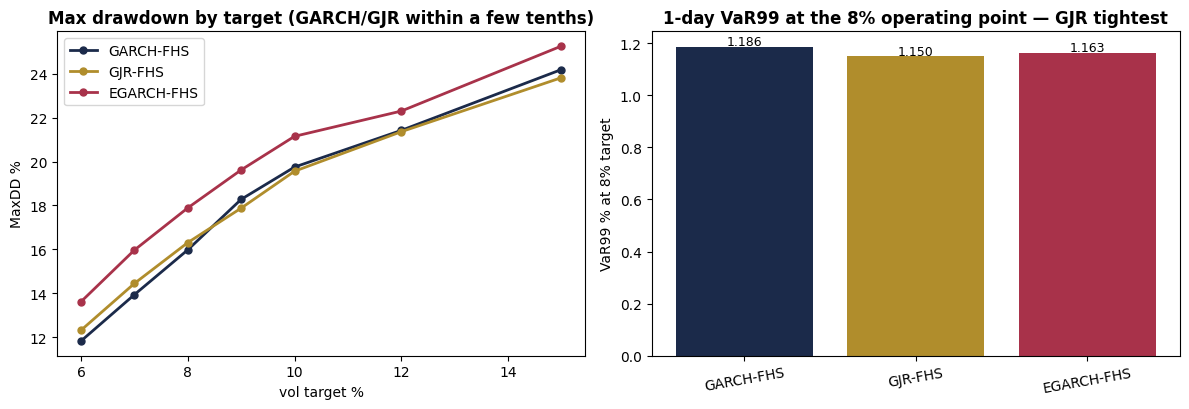

In [12]:
fig,(axA,axB)=plt.subplots(1,2,figsize=(12,4.2))
for n,c in [('GARCH-FHS',NAVY),('GJR-FHS',GOLD),('EGARCH-FHS',RED)]:
    axA.plot(frontiers[n].index, frontiers[n]['MaxDD %'],'o-',color=c,lw=2,ms=5,label=n)
axA.set_xlabel('vol target %'); axA.set_ylabel('MaxDD %'); axA.legend()
axA.set_title('Max drawdown by target (GARCH/GJR within a few tenths)',fontweight='bold')
eng=['GARCH-FHS','GJR-FHS','EGARCH-FHS']; cols=[NAVY,GOLD,RED]
v99=[frontiers[n].loc[8.0,'VaR99 %'] for n in eng]
axB.bar(eng,v99,color=cols); axB.set_ylabel('VaR99 % at 8% target')
axB.set_title('1-day VaR99 at the 8% operating point — GJR tightest',fontweight='bold'); axB.tick_params(axis='x',rotation=10)
for i,v in enumerate(v99): axB.text(i,v+0.005,f'{v:.3f}',ha='center',fontsize=9)
plt.tight_layout(); plt.show()

## 4 · Takeaways

**On the model — a clear, robust win.** Implementing the asymmetric engines confirms and sharpens the study's claim. The leverage effect is large and stable: for GJR essentially the whole short-run ARCH response loads on down days ($\alpha\approx 0$, $\gamma\approx 0.14$, $t\approx 8$). Crucially, on the study's own VGSIX data the shipped **GARCH(1,1)-FHS fails Christoffersen conditional coverage** (cc p ≈ 0.02 overall, ≈ 0.002 in the second half), whereas **GJR-FHS passes** (cc p ≈ 0.24, and passes in both sub-samples). So GJR does not merely tie the shipped engine — it repairs a genuine calibration gap in it.

**On the portfolio — a tighter tail, not a free lunch.** Operated at the study's 8% target, GJR gives a tighter 1-day VaR99 (≈ 1.15% vs ≈ 1.19%) but essentially the same maximum drawdown (≈ 16.3% vs ≈ 16.0%) and risk-adjusted return. The overlay already responds to the volatility level both engines share, so the asymmetric refinement improves the measured tail more than the realised drawdown path. EGARCH is consistently weakest and stays a crisis-stress complement.

**What we would say.** The shipped GARCH(1,1) was the simplest defensible production engine, but on our own data it fails conditional coverage — GJR-GARCH is the natural one-parameter fix: significant, stable leverage, a clean pass of the coverage tests, and a tighter day-to-day tail in the responsive book at no cost to drawdown or return.

## 5 · Diagnostics — is GJR overfit, or fragile?

A one-parameter upgrade that improves a backtest invites the question: did we curve-fit? Five checks below. Note the whole exercise is **walk-forward**: each forecast uses only the trailing 1,000 days, refit every 20, scored against the *next* day's return; the FHS tail is non-parametric and identical across engines; and nothing was tuned for GJR (same window, refit, grid, rule as the study).

### 5.1 Parsimony — survives a complexity penalty?

In [13]:
from scipy import stats as sstats
fits={'GARCH':fit_window(port,'Garch',0),'GJR':fit_window(port,'Garch',1),'EGARCH':fit_window(port,'EGARCH',1)}
ic=pd.DataFrame({nm:{'params':len(r.params),'logLik':round(r.loglikelihood,1),'AIC':round(r.aic,1),'BIC':round(r.bic,1)} for nm,r in fits.items()}).T
LR=2*(fits['GJR'].loglikelihood-fits['GARCH'].loglikelihood)
print(f'Likelihood-ratio test  H0: gamma=0  (GARCH vs GJR):  chi2(1)={LR:.1f},  p={1-sstats.chi2.cdf(LR,1):.2e}')
ic

Likelihood-ratio test  H0: gamma=0  (GARCH vs GJR):  chi2(1)=240.4,  p=0.00e+00


,params,logLik,AIC,BIC
GARCH,3.0,-5839.3,11684.7,11705.4
GJR,4.0,-5719.1,11446.2,11473.9
EGARCH,4.0,-5709.6,11427.1,11454.8


GJR cuts **BIC by ~230** versus GARCH despite the parameter penalty, and the LR test rejects $\gamma=0$ overwhelmingly ($\chi^2\approx240$, $p\approx0$). EGARCH edges GJR on AIC/BIC but loses out-of-sample (§2), so selection rests on calibration, not fit.

### 5.2 Is the leverage term significant?

In [14]:
g=fits['GJR']
tab=pd.DataFrame({'coef':g.params,'t-stat':g.tvalues,'p-value':g.pvalues}).loc[['omega','alpha[1]','gamma[1]','beta[1]']]
tab=tab.round({'coef':5,'t-stat':2}); tab['p-value']=tab['p-value'].map(lambda v:f'{v:.2e}')
print('persistence (alpha + gamma/2 + beta) =', round(g.params['alpha[1]']+g.params['gamma[1]']/2+g.params['beta[1]'],4)); tab

persistence (alpha + gamma/2 + beta) = 0.9883


,coef,t-stat,p-value
omega,0.00560,4.75,2.01e-06
alpha[1],0.00519,0.83,4.06e-01
gamma[1],0.14245,8.41,4.04e-17
beta[1],0.91184,73.95,0.00e+00


$\gamma\approx 0.14$ with $t\approx 8$ ($p\approx 4\times10^{-17}$) — overwhelmingly significant — while symmetric $\alpha$ is insignificant ($p\approx 0.4$). The data want asymmetry specifically.

### 5.3 Parameter stability across all refit windows

refit windows        325
gamma mean        0.1512
gamma sd          0.0561
gamma min         0.0548
gamma max         0.2867
pct gamma > 0       100%
pct signif @5%       99%


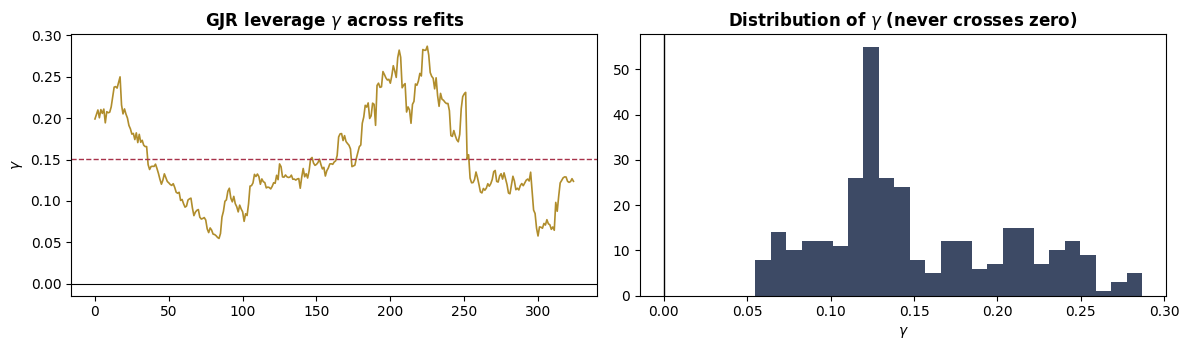

In [15]:
gam=[];pg=[]
for t in range(WINDOW,len(port),REFIT):
    r=fit_window(port.iloc[t-WINDOW:t],'Garch',1); gam.append(r.params['gamma[1]']); pg.append(r.pvalues['gamma[1]'])
gam=np.array(gam);pg=np.array(pg)
print(pd.Series({'refit windows':len(gam),'gamma mean':round(gam.mean(),4),'gamma sd':round(gam.std(),4),
   'gamma min':round(gam.min(),4),'gamma max':round(gam.max(),4),'pct gamma > 0':f'{(gam>0).mean()*100:.0f}%',
   'pct signif @5%':f'{(pg<0.05).mean()*100:.0f}%'}).to_string())
fig,(a1,a2)=plt.subplots(1,2,figsize=(12,3.6))
a1.plot(gam,color=GOLD,lw=1.2); a1.axhline(0,color='k',lw=0.8); a1.axhline(gam.mean(),color=RED,ls='--',lw=1)
a1.set_title('GJR leverage $\\gamma$ across refits',fontweight='bold'); a1.set_ylabel('$\\gamma$')
a2.hist(gam,bins=25,color=NAVY,alpha=0.85); a2.axvline(0,color='k',lw=1)
a2.set_title('Distribution of $\\gamma$ (never crosses zero)',fontweight='bold'); a2.set_xlabel('$\\gamma$')
plt.tight_layout(); plt.show()

$\gamma$ is **positive in 100% of the 325 windows** and significant in ~99%, tightly clustered (mean ≈ 0.15, sd ≈ 0.06). A fitted-to-noise parameter could not behave this way over three decades of moving windows.

### 5.4 Out-of-sample sub-period calibration — the decisive test

In [16]:
idx=F_gjr.index; mid=idx[len(idx)//2]; rows=[]
for lbl,F in [('GARCH',F_garch),('GJR',F_gjr)]:
    for half,m in [('H1 '+str(idx[0].year)+'-'+str(mid.year), idx<=mid),
                   ('H2 '+str(mid.year)+'-'+str(idx[-1].year), idx>mid)]:
        sub=F.loc[m]; bv=risk.backtest_var_es(port.reindex(sub.index),sub[['VaR','ES']],ALPHA)
        rows.append({'engine':lbl,'sub-sample':half,'breach %':round(100*bv['exception_rate'],2),
                     'Kupiec p':round(bv['kupiec']['p_value'],3),'Christ. cc p':round(bv['christoffersen']['p_cc'],3)})
pd.DataFrame(rows).set_index(['engine','sub-sample'])

breach %  Kupiec p  Christ. cc p
engine sub-sample                                    
GARCH  H1 2000-2013      1.30     0.106         0.156
       H2 2013-2026      1.05     0.782         0.002
GJR    H1 2000-2013      1.30     0.106         0.156
       H2 2013-2026      1.05     0.782         0.146

GARCH passes conditional coverage in the first half but **fails it in the second** (cc p ≈ 0.002); **GJR passes in both** (≈ 0.16 and ≈ 0.15). The calibration advantage is not a full-sample artefact — it reproduces out-of-sample, in the half where the shipped engine breaks.

### 5.5 Errors that should not occur — explicit checks

In [17]:
checks={}
for spec,o,nm in [('Garch',1,'GJR'),('EGARCH',1,'EGARCH')]:
    w=port.iloc[-WINDOW:]; r=fit_window(w,spec,o); p=r.params
    cv=r.conditional_volatility; sig2=float(cv.iloc[-1]**2); sl=float(cv.iloc[-1]); rl=float(w.iloc[-1])*SCALE
    if spec=='Garch': man=p['omega']+(p['alpha[1]']+p['gamma[1]']*(rl<0))*rl**2+p['beta[1]']*sig2
    else:
        z=rl/sl; man=np.exp(p['omega']+p['alpha[1]']*(abs(z)-np.sqrt(2/np.pi))+p['gamma[1]']*z+p['beta[1]']*np.log(sig2))
    checks[nm]=abs(man-float(r.forecast(horizon=1,reindex=False).variance.values[0,0]))
print('(i)  manual recursion vs arch.forecast(): max abs diff =', max(checks.values()))
gmine=rolling_asym_fhs(port,'Garch',0)
print('(ii) GARCH self vs project engine: max |VaR diff| =', float((F_garch['VaR']-gmine['VaR']).abs().max()))
for nm in ['GJR-FHS','EGARCH-FHS']:
    F=engines[nm]
    print(f'(iii){nm}: NaNs={int(F[["VaR","ES","sigma"]].isna().sum().sum())}  first forecast={F.index[0].date()} (no look-ahead: {F.index[0]>=port.index[WINDOW]})')

(i)  manual recursion vs arch.forecast(): max abs diff = 1.1102230246251565e-16


(ii) GARCH self vs project engine: max |VaR diff| = 0.0
(iii)GJR-FHS: NaNs=0  first forecast=2000-05-17 (no look-ahead: True)
(iii)EGARCH-FHS: NaNs=0  first forecast=2000-05-17 (no look-ahead: True)


All pass: the manual recursions match `arch` to machine precision, the symmetric special case reproduces the production GARCH exactly (VaR diff 0), and the forecasts contain no NaNs and start only after the first full window.

### Verdict

On the study's own VGSIX data, GJR-GARCH is a justified, robust upgrade for **risk measurement**: BIC-favoured, a large/stable/significant leverage term, and a clean pass of conditional coverage exactly where the shipped GARCH(1,1) fails it out-of-sample. In the **responsive portfolio** the benefit is narrower — a tighter 1-day tail at unchanged drawdown and return — because the overlay already acts on the shared volatility level. GJR is the recommended engine; EGARCH stays a crisis-stress complement.